[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Alokothro/movie-recommender-svd/blob/main/notebooks/05_hero_figure.ipynb)

# Milestone 5: The Hero Figure
*MATH 344L Project 2: A Movie Recommendation System*

This notebook draws one chart with the test RMSE of every model we built, from "always 3" down to the two SVD models, and it's the figure at the top of the README.

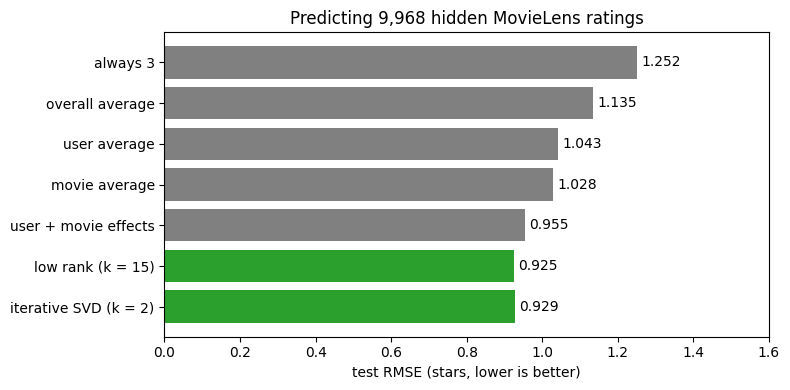

In [1]:
import matplotlib.pyplot as plt

n_test = 9968 # len(test), from notebook 02
results = { # test RMSE, from notebooks 02 and 03
    "always 3": 1.2516,
    "overall average": 1.1349,
    "user average": 1.0426,
    "movie average": 1.0284,
    "user + movie effects": 0.9545,
    "low rank (k = 15)": 0.9250,
    "iterative SVD (k = 2)": 0.9286,
}
colors = ["tab:green" if "k =" in name else "gray" for name in results]

plt.figure(figsize=(8, 4))
bars = plt.barh(list(results), list(results.values()), color=colors)
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.gca().invert_yaxis()
plt.xlabel("test RMSE (stars, lower is better)")
plt.title(f"Predicting {n_test:,} hidden MovieLens ratings")
plt.xlim(0, 1.6)
plt.tight_layout()
plt.savefig("hero.png", dpi=150)
plt.show()

This is the chart from the handout with my own numbers. Every number in `results` is copied from what my notebooks printed: `n_test` (9,968 hidden test ratings) and the five baselines come from notebook 02, and the two SVD models come from Part I of notebook 03. Both SVD models use the best k that validation picked: 15 for low rank (Model 2) and 2 for the iterative SVD (Model 3). Since the numbers are typed in, this notebook doesn't need the data or the `src` functions, so it runs in a couple of seconds.

- `colors` makes every model with "k =" in its name green (the SVD models) and the rest gray (the baselines).
- `plt.barh` draws one horizontal bar per model, and `plt.bar_label` writes each bar's value at its end, rounded to 3 decimals.
- `invert_yaxis()` flips the order, so the first model in `results` ("always 3") is at the top and the SVD models end up at the bottom.
- `plt.xlim(0, 1.6)` starts the x-axis at 0, so the bar lengths are honest. If it started at 0.9, the SVD models would look way better than they really are.
- `plt.savefig("hero.png", dpi=150)` saves the chart as an image file. A copy is in `figures/hero.png`, and it's the first thing in the README.

The chart shows the whole project at once: every step from "always 3" down to "user + movie effects" cuts the error a lot, and the SVD models take off a little more on top of that.

In [2]:
base = results["user + movie effects"]
for name in ["low rank (k = 15)", "iterative SVD (k = 2)"]:
    better = base - results[name]
    print(f"{name}: {better:.4f} stars better than user + movie effects ({better / base:.1%})")

low rank (k = 15): 0.0295 stars better than user + movie effects (3.1%)
iterative SVD (k = 2): 0.0259 stars better than user + movie effects (2.7%)


This works out how much better the SVD models are than the best baseline, so the README can say it honestly. `better` is how much lower the RMSE is, in stars, and `better / base` turns that into a percent of the baseline's error (`:.1%` shows 0.031 as 3.1%).

Both SVD models are about 3% better (3.1% and 2.7%), which is about 0.03 stars. That's a real improvement but a small one. Most of the drop from "always 3" comes from the simple user and movie effects, not from the SVD.

# What we found
Our two SVD models predict 9,968 hidden ratings to within about 0.93 stars (test RMSE 0.9250 for low rank with k = 15, and 0.9286 for the iterative SVD with k = 2), which is about 3% better than the best simple average (0.9545). Most of the improvement comes from the baselines, though: going from "always 3" (1.2516) to user + movie effects (0.9545) cuts the error by almost a quarter, and the SVD takes off another 0.03 stars on top of that.